# A1 diagnostics — why is EER high?

Reads existing score CSVs. **No audio extraction, GMM fitting, or evaluation rerun.** Higher scores mean bona fide. Change `RUN` to your evaluation folder.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

RUN = Path("../runs/E-20261019-184305-433338-a1")
SPLIT = "eval"  # "eval" or "itw"
score_path = RUN / "scores" / f"{SPLIT}.csv"
assert score_path.exists(), f"Not found: {score_path}"
df = pd.read_csv(score_path)
required = {"label", "score"}
assert required <= set(df.columns), f"Missing columns: {required - set(df.columns)}"
df = df.dropna(subset=["label", "score"]).copy()
df["label"] = df["label"].astype(str).str.lower().str.strip()
assert set(df.label.unique()) <= {"bonafide", "spoof"}
assert set(df.label.unique()) == {"bonafide", "spoof"}, "Both classes needed for EER"
print(f"{SPLIT}: {len(df):,} clips")
print(df.groupby("label")["score"].agg(["count", "mean", "median", "std"]).round(3))

eval: 71,237 clips
          count   mean  median    std
label                                
bonafide   7355  0.373   0.397  0.399
spoof     63882 -0.818  -0.580  1.160


## 1. Score overlap
A1 uses a likelihood ratio. Higher = more bona fide. Heavy overlap suggests weak separation, while a bad fixed-threshold F1 can also reflect threshold transfer.

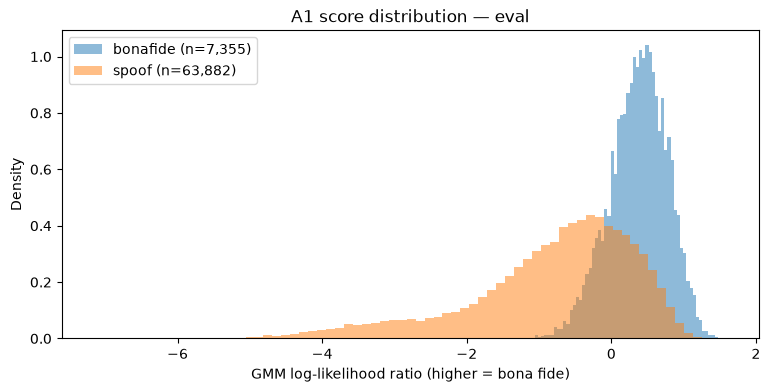

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
for label in ["bonafide", "spoof"]:
    scores = df.loc[df.label == label, "score"].to_numpy()
    ax.hist(scores, bins=70, density=True, alpha=.5, label=f"{label} (n={len(scores):,})")
ax.set(xlabel="GMM log-likelihood ratio (higher = bona fide)", ylabel="Density", title=f"A1 score distribution — {SPLIT}")
ax.legend()
plt.show()

## 2. EER and AUC
Computed here for **diagnosis**, not to replace the project’s official metric implementation. Exact EER may differ slightly due to interpolation conventions. An EER of 22% means the error rates meet near 22% at an evaluation-dependent threshold; 

Diagnostic EER ≈ 22.35%
ROC AUC = 0.8572
EER operating threshold (diagnostic only) ≈ 0.0836


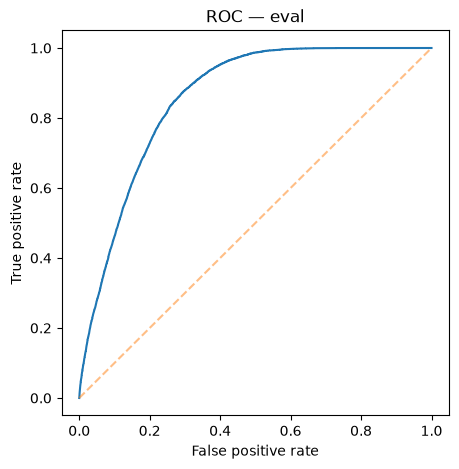

In [5]:
y = (df.label == "bonafide").astype(int).to_numpy()
scores = df.score.to_numpy(dtype=float)
fpr, tpr, thresholds = roc_curve(y, scores)
fnr = 1 - tpr
ix = int(np.argmin(np.abs(fpr - fnr)))
print(f"Diagnostic EER ≈ {(fpr[ix] + fnr[ix]) / 2:.2%}")
print(f"ROC AUC = {roc_auc_score(y, scores):.4f}")
print(f"EER operating threshold (diagnostic only) ≈ {thresholds[ix]:.4f}")
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr)
ax.plot([0, 1], [0, 1], '--', alpha=.5)
ax.set(xlabel="False positive rate", ylabel="True positive rate", title=f"ROC — {SPLIT}")
plt.show()

## 3. Per-attack EER
Each spoof attack is compared against **the same bona fide clips**. This is a diagnostic breakdown, not the pooled benchmark score.

,attack,n_spoof,eer_pct
11,A18,4914,53.829987
12,A19,4914,47.772637
10,A17,4914,26.432838
5,A12,4914,24.286986
9,A16,4914,22.789621
3,A10,4914,18.851019
0,A07,4914,16.375791
6,A13,4914,13.880213
4,A11,4914,8.515561
8,A15,4914,7.775365


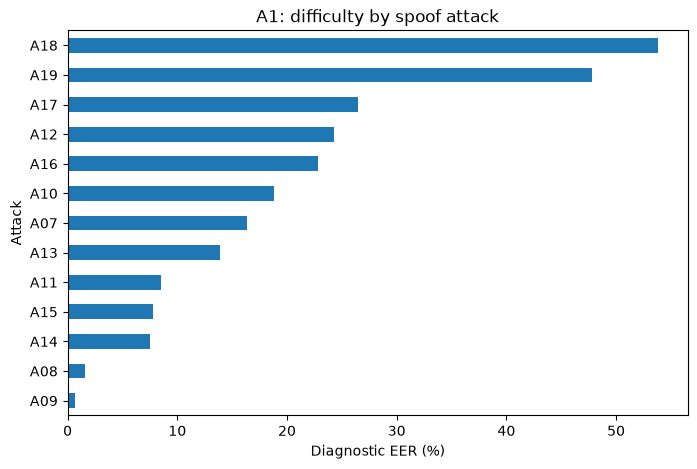

In [6]:
if "attack_id" not in df:
    print("No attack_id column; skipping per-attack analysis.")
else:
    bona = df[df.label == "bonafide"]
    rows = []
    attacks = df[df.label == "spoof"].groupby("attack_id")
    for attack, spoof in attacks:
        pair = pd.concat([bona, spoof], ignore_index=True)
        yy = (pair.label == "bonafide").astype(int).to_numpy()
        ff, tt, _ = roc_curve(yy, pair.score.to_numpy())
        miss = 1 - tt
        i = int(np.argmin(np.abs(ff - miss)))
        rows.append({"attack": attack, "n_spoof": len(spoof), "eer_pct": 50 * (ff[i] + miss[i])})
    attack_df = pd.DataFrame(rows).sort_values("eer_pct", ascending=False)
    display(attack_df)
    ax = attack_df.sort_values("eer_pct").plot.barh(x="attack", y="eer_pct", legend=False, figsize=(8, 5))
    ax.set(xlabel="Diagnostic EER (%)", ylabel="Attack", title="A1: difficulty by spoof attack")
    plt.show()

## 4. Inspect high-confidence mistakes (optional)
Requires a **dev-selected threshold**. Never use the evaluation EER threshold as if it were a deployed decision threshold. Set the threshold below to the one stored in your run metadata, if available.

In [7]:
DEV_THRESHOLD = None  # e.g. -0.42, from dev calibration; do not fit on eval
if DEV_THRESHOLD is None:
    print("Set DEV_THRESHOLD from dev results to inspect actual false accepts/rejects.")
else:
    predicted_bona = scores >= DEV_THRESHOLD
    actual_bona = y == 1
    wrong = df.loc[predicted_bona != actual_bona].copy()
    wrong["error"] = np.where(wrong.label == "spoof", "false accept", "false reject")
    print(wrong["error"].value_counts())
    cols = [c for c in ["clip_id", "label", "attack_id", "score", "error"] if c in wrong]
    display(wrong[cols].head(20))

Set DEV_THRESHOLD from dev results to inspect actual false accepts/rejects.
